<a href="https://colab.research.google.com/github/Anshikatyagi008/EDA-Projects/blob/main/eda/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/creditcard.csv')

In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
91195,63353,-0.490895,1.107765,1.502218,0.848157,0.424492,-0.116355,0.801624,0.093389,-1.189178,...,0.145558,0.422849,-0.246593,0.229489,0.107284,-0.263054,0.110716,0.094024,4.99,0.0
91196,63353,1.263123,-0.735270,-0.001407,-0.796592,-0.759490,-0.369354,-0.406820,-0.057882,-1.063382,...,-0.545363,-1.335962,0.035395,-0.359533,0.081162,0.835179,-0.081592,0.004941,79.38,0.0
91197,63354,-0.223639,1.073431,1.331846,0.463195,0.135678,-0.881074,0.708761,-0.181839,-0.726279,...,-0.143288,-0.387236,0.056717,0.371521,-0.702896,0.084805,0.140208,0.177478,6.99,0.0
91198,63354,1.135869,-1.278531,0.076387,-0.002852,0.679808,4.766929,-1.836080,1.259028,0.439912,...,-0.508605,-0.798310,-0.081020,0.996750,0.571672,-0.268628,0.118991,0.046959,75.00,0.0
91199,63354,-5.923850,5.078018,-3.223655,1.053491,-3.230265,-0.405473,-2.966812,4.288420,0.272339,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.columns.tolist()

['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount',
 'Class']

In [ ]:
df.shape

(91200, 31)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91200 entries, 0 to 91199
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    91200 non-null  int64  
 1   V1      91200 non-null  float64
 2   V2      91200 non-null  float64
 3   V3      91200 non-null  float64
 4   V4      91200 non-null  float64
 5   V5      91200 non-null  float64
 6   V6      91200 non-null  float64
 7   V7      91200 non-null  float64
 8   V8      91200 non-null  float64
 9   V9      91200 non-null  float64
 10  V10     91200 non-null  float64
 11  V11     91200 non-null  float64
 12  V12     91200 non-null  float64
 13  V13     91200 non-null  float64
 14  V14     91200 non-null  float64
 15  V15     91199 non-null  float64
 16  V16     91199 non-null  float64
 17  V17     91199 non-null  float64
 18  V18     91199 non-null  float64
 19  V19     91199 non-null  float64
 20  V20     91199 non-null  float64
 21  V21     91199 non-null  float64
 22

In [ ]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,91200.000000,91200.000000,91200.000000,91200.000000,91200.000000,91200.000000,91200.000000,91200.000000,91200.000000,91200.000000,...,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000
mean,40218.724474,-0.263489,-0.040218,0.677104,0.162761,-0.279624,0.094647,-0.108948,0.054542,-0.033586,...,-0.029791,-0.107291,-0.037484,0.009603,0.132399,0.027111,0.001449,0.002511,98.836868,0.002314
std,16208.216858,1.871579,1.662459,1.347185,1.357217,1.370698,1.303795,1.228957,1.214456,1.125841,...,0.727355,0.635203,0.626381,0.594322,0.441172,0.496222,0.389847,0.325301,268.042772,0.048045
min,0.000000,-56.407510,-72.715728,-33.680984,-5.172595,-42.147898,-26.160506,-31.764946,-73.216718,-9.283925,...,-34.830382,-10.933144,-26.751119,-2.836627,-7.495741,-2.534330,-9.390980,-9.617915,0.000000,0.000000
25%,32437.750000,-1.028050,-0.605011,0.180264,-0.718001,-0.898175,-0.646850,-0.601624,-0.139681,-0.694838,...,-0.224139,-0.527338,-0.177541,-0.321921,-0.132304,-0.325760,-0.063155,-0.005671,7.610000,0.000000
50%,42416.000000,-0.259193,0.072606,0.758381,0.186746,-0.313804,-0.156329,-0.070197,0.071889,-0.105892,...,-0.057803,-0.082281,-0.049619,0.064768,0.171213,-0.070650,0.009497,0.023228,26.980000,0.000000
75%,52976.250000,1.152942,0.727724,1.383181,1.035486,0.252585,0.488617,0.415907,0.355994,0.582092,...,0.119049,0.309107,0.081231,0.405899,0.420183,0.305754,0.082692,0.076445,89.980000,0.000000
max,63354.000000,1.960497,18.902453,4.226108,16.715537,34.801666,22.529298,36.677268,20.007208,10.392889,...,22.614889,10.503090,18.946734,4.014444,5.541598,3.517346,12.152401,33.847808,19656.530000,1.000000


In [ ]:
df.dtypes

,0
Time,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


In [ ]:
df.isnull()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91195,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
91196,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
91197,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
91198,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.loc[:, 'V1':'V28'] = df.loc[:, 'V1':'V28'].fillna(
    df.loc[:, 'V1':'V28'].median()
)

df['Amount'] = df['Amount'].fillna(df['Amount'].median())

In [ ]:
df[df.isnull().any(axis=1)]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
91199,63354,-5.92385,5.078018,-3.223655,1.053491,-3.230265,-0.405473,-2.966812,4.28842,0.272339,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.dropna(subset=['Class'], inplace=True)

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 321


In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Shape after removing duplicates: (283726, 31)
Duplicates remaining: 0


In [ ]:
df[df.isnull().any(axis=1)]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


In [ ]:
df.duplicated().sum().sum()

np.int64(0)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
print(df['Class'].value_counts())

Class
0.0    90667
1.0      211
Name: count, dtype: int64


In [ ]:
df.dtypes

,0
Time,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


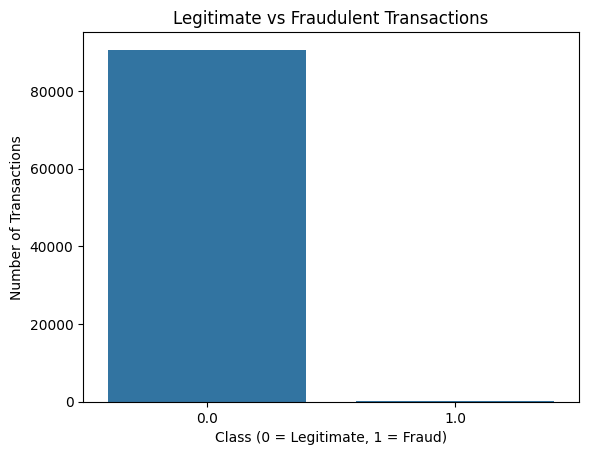

In [ ]:
sns.countplot(x='Class', data=df)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

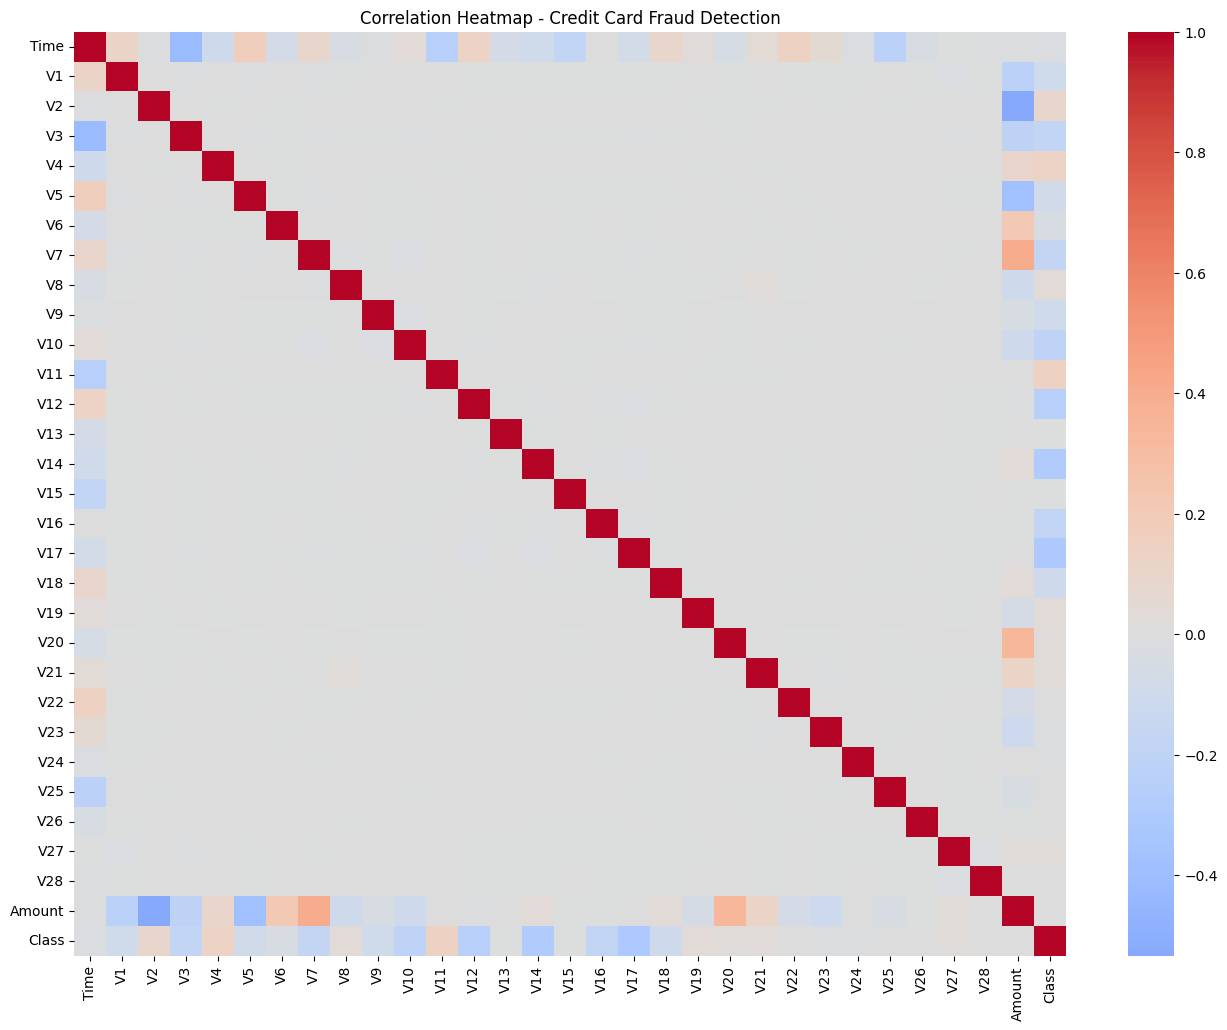

In [ ]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    df.corr(),
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap - Credit Card Fraud Detection")
plt.show()

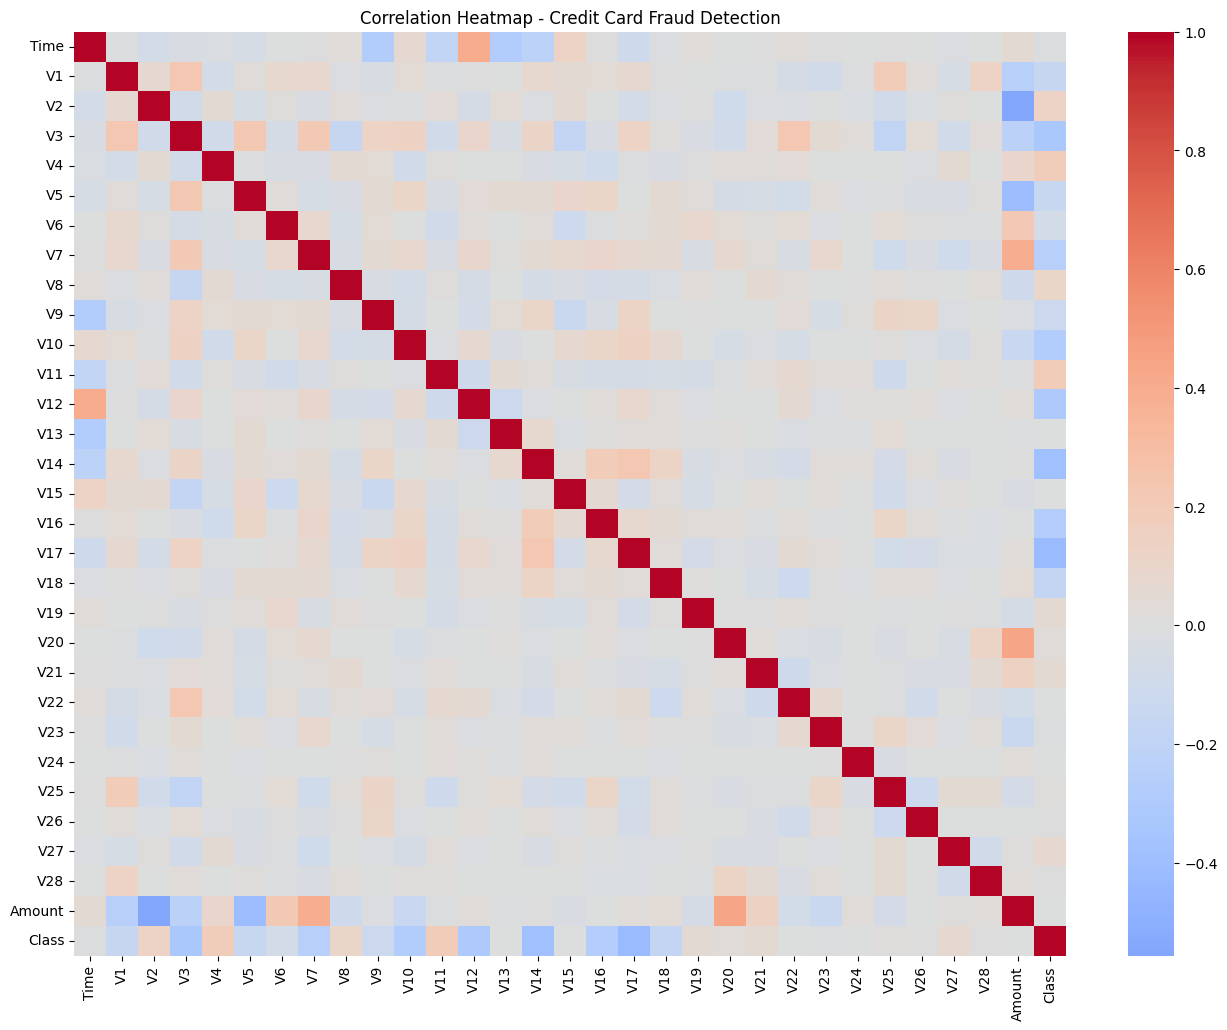

In [ ]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - Credit Card Fraud Detection")
plt.show()

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Categorical: []


In [ ]:
X = df.drop('Class', axis=1)
y = df['Class']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(226980, 30)
(56746, 30)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (226980, 30)
Testing data shape: (56746, 30)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the model
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
log_reg.fit(X_train_scaled, y_train)

# Predict on test data
y_pred_log = log_reg.predict(X_test_scaled)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

Accuracy: 0.9991188806259472

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix:
[[56641    10]
 [   40    55]]
